# Madurez del limón sutil: análisis del Avance 1 (Grupo 3)

Este notebook calcula las tablas y figuras que faltan en las secciones 4, 5 y 6 del informe.

**Antes de correr:**
1. `Entorno de ejecución > Cambiar tipo de entorno de ejecución > GPU (T4)`.
2. En Drive, haz clic derecho en la carpeta `etiquetado` > **Descargar**. Drive te da un `.zip`.
3. Corre las celdas en orden. En la celda 2.1 aparece un botón **Elegir archivos**: sube ese `.zip`.

El zip debe tener una carpeta por clase: `verde/`, `pinton/`, `maduro/` (las demás se ignoran).
Al final se descarga `resultados.zip` con las tablas (CSV), las figuras (PNG) y `resumen_informe.txt`.

**Ojo:** al copiar el notebook como texto solo se copia el código, no lo que imprime. Para mostrar un resultado, toma una captura de la salida de la celda.

## 1. Librerías
**Informe:** 4.8 Herramientas utilizadas

PyWavelets: extraer características como detalles, bordes y texturas
MLflow: Registra parámetros, métricas y modelos entrenados
torchinfo:

In [1]:
# 1.1 Instalar librerías  ->  Informe: 4.8 Herramientas utilizadas
!pip -q install PyWavelets mlflow torchinfo pillow-heif pyspark

In [2]:
# 1.2 Importar librerías  ->  Informe: 4.8 Herramientas utilizadas
import os, sys, time, hashlib, random, shutil, platform, zipfile, glob
import numpy as np, pandas as pd, cv2, matplotlib.pyplot as plt
from PIL import Image, ImageOps
import pywt
from skimage.feature import hog, local_binary_pattern
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, f1_score, recall_score, precision_score, precision_recall_fscore_support,
                             confusion_matrix, ConfusionMatrixDisplay)
import json, copy, inspect
import torch, torch.nn as nn, torchvision
from torchvision import transforms, models
import mlflow
try:
    from pillow_heif import register_heif_opener; register_heif_opener()      # fotos HEIC de celular
except ImportError:
    pass
EN_COLAB = "google.colab" in sys.modules
print("Listo. PyTorch", torch.__version__, "| GPU:", torch.cuda.is_available())

Listo. PyTorch 2.14.1+cu130 | GPU: True


## 2. Descargar el dataset desde Drive y parámetros

In [3]:
# 2.1 Descargar el dataset desde Google Drive  ->  Informe: 4.1 Fuentes de datos · 5.4 Proceso de entrenamiento (parámetros)
#@markdown Enlace de la carpeta **etiquetado_final_agregarfotos** (la que tiene Ark, Franco, Guinno y Leoncio).
CARPETA_DRIVE = "https://drive.google.com/drive/folders/1KqT60QOlIsdWQMDNuu0GVYzsaB4-WwLy"  #@param {type:"string"}
#@markdown Enlace de la copia del parcial **etiquetado_avance1** (sirve para saber qué fotos son antiguas).
CARPETA_AVANCE1 = "https://drive.google.com/drive/folders/1cdC6sah1bsUlJzsVQ73LsvLIjOQjuPKE"  #@param {type:"string"}
#@markdown Marca para entrenar **solo con las fotos nuevas** (sin las del parcial).
SOLO_NUEVAS = False  #@param {type:"boolean"}

import re, io, concurrent.futures, threading
CLASES = ["verde", "pinton", "maduro"]          # orden de las clases (0, 1, 2)
PATRON_NOMBRE = re.compile(r"^([vpm])_([A-Za-z0-9]+)_(\d{3})\.jpe?g$", re.I)   # ej. v_A26_601.jpg
BASE = "/content" if EN_COLAB else os.getcwd()
DESTINO = os.path.join(BASE, "dataset")
RUTA_DATASET = DESTINO

if EN_COLAB:
    from google.colab import auth, files
    auth.authenticate_user()                     # pide permiso a tu cuenta de Google (solo lectura de lo que ya puedes ver)
    from googleapiclient.discovery import build
    import google.auth
    CRED, _ = google.auth.default()
_local = threading.local()
def servicio():
    """Un cliente de Drive por hilo (para descargar varias fotos a la vez)."""
    if not EN_COLAB: return drive                # (fuera de Colab se usa un Drive de prueba)
    if not hasattr(_local, "s"): _local.s = build("drive", "v3", credentials=CRED, cache_discovery=False)
    return _local.s

def id_de(url):
    m = re.search(r"folders/([A-Za-z0-9_-]+)", url); return m.group(1) if m else url.strip()

def listar(padre, carpetas=False):
    q = f"'{padre}' in parents and trashed = false and mimeType " + ("=" if carpetas else "!=") + " 'application/vnd.google-apps.folder'"
    res, token = [], None
    while True:
        r = servicio().files().list(q=q, pageSize=1000, pageToken=token, supportsAllDrives=True, includeItemsFromAllDrives=True,
              fields="nextPageToken, files(id, name, mimeType, md5Checksum, size, createdTime, owners(emailAddress))").execute()
        res += r.get("files", []); token = r.get("nextPageToken")
        if not token: return res

# 1) recorrer Integrante/clase_integrante
inventario = []
for integ in sorted(listar(id_de(CARPETA_DRIVE), carpetas=True), key=lambda f: f["name"]):
    for sub in listar(integ["id"], carpetas=True):
        clase = next((c for c in CLASES if sub["name"].lower().startswith(c)), None)
        if clase is None:                         # otras carpetas (descartadas, etc.) no se usan
            continue
        for f in listar(sub["id"]):
            if f.get("mimeType", "").startswith("image/"):
                inventario.append(dict(integrante=integ["name"], clase=clase, **f))
assert inventario, "No encontré fotos: revisa el enlace de la carpeta"

# 2) huellas MD5 de la copia del parcial (para marcar fotos antiguas), sin descargarla
def huellas(padre):
    h = {f.get("md5Checksum") for f in listar(padre)}
    for c in listar(padre, carpetas=True): h |= huellas(c["id"])
    return h
MD5_AVANCE1 = huellas(id_de(CARPETA_AVANCE1)) if CARPETA_AVANCE1.strip() else set()

# 3) descargar (en paralelo; si la foto ya está descargada con el mismo tamaño, no se baja de nuevo)
usados = set()
for f in inventario:
    nombre = f["name"] if os.path.splitext(f["name"])[1] else f["name"] + ".jpg"   # Drive a veces guarda sin extensión
    carpeta = os.path.join(DESTINO, f["integrante"], f["clase"])
    if (carpeta, nombre.lower()) in usados:                                       # nombres repetidos (fotos sin renombrar)
        base_, ext_ = os.path.splitext(nombre); nombre = f"{base_}__{f['id'][:6]}{ext_}"
    usados.add((carpeta, nombre.lower())); f["local"] = os.path.join(carpeta, nombre)

def bajar(f):
    os.makedirs(os.path.dirname(f["local"]), exist_ok=True)
    if os.path.exists(f["local"]) and os.path.getsize(f["local"]) == int(f.get("size", -1)): return 0
    datos = servicio().files().get_media(fileId=f["id"], supportsAllDrives=True).execute()
    open(f["local"], "wb").write(datos); return 1
t0 = time.time()
with concurrent.futures.ThreadPoolExecutor(8) as ex:
    nuevas_bajadas = sum(ex.map(bajar, inventario))
print(f"{len(inventario)} fotos en Drive ({nuevas_bajadas} descargadas ahora) en {time.time() - t0:.0f} s")

ORIGEN = pd.DataFrame([dict(ruta=f["local"], integrante=f["integrante"], clase=f["clase"], nombre_drive=f["name"],
                            id_drive=f["id"], dueño=(f.get("owners") or [{}])[0].get("emailAddress", ""),
                            subida=f.get("createdTime", ""), antigua=f.get("md5Checksum") in MD5_AVANCE1) for f in inventario])
print(pd.crosstab(ORIGEN.integrante, ORIGEN.clase).reindex(columns=CLASES, fill_value=0).assign(Total=lambda t: t.sum(axis=1)).to_string())
print(f"\nAntiguas (del parcial): {ORIGEN.antigua.sum()} · Nuevas: {(~ORIGEN.antigua).sum()} · SOLO_NUEVAS = {SOLO_NUEVAS}")
sin_nombre = ORIGEN[~ORIGEN.nombre_drive.str.match(PATRON_NOMBRE)]
if len(sin_nombre): print(f"OJO: {len(sin_nombre)} fotos aún sin el nombre acordado (se usan igual; el celular queda 'sin código'):",
                          sin_nombre.groupby("integrante").size().to_dict())

236 fotos en Drive (236 descargadas ahora) en 43 s
clase       verde  pinton  maduro  Total
integrante                              
Ark            63      34      51    148
Franco         23       0      23     46
Guinno         16       0      10     26
Leoncio         2      10       4     16

Antiguas (del parcial): 105 · Nuevas: 131 · SOLO_NUEVAS = False


In [4]:
# 2.2 Parámetros del experimento  ->  Informe: 4.1 Fuentes de datos · 5.4 Proceso de entrenamiento (parámetros)
SALIDA = os.path.join(BASE, "resultados")
FIG, TAB = os.path.join(SALIDA, "figuras"), os.path.join(SALIDA, "tablas")
shutil.rmtree(SALIDA, ignore_errors=True)
os.makedirs(FIG, exist_ok=True); os.makedirs(TAB, exist_ok=True)

NOMBRE = {"verde": "Verde", "pinton": "Pintón", "maduro": "Maduro"}
SEED = 42
SEMILLAS = [42, 7, 123]                         # tres semillas para media y desviación estándar
EPOCAS = int(os.environ.get("EPOCAS", 30))
LR = 1e-4
TAM = 224
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
EXT = (".jpg", ".jpeg", ".png", ".webp", ".jfif", ".bmp", ".heic", ".heif")
# ---- Lógica del proyecto (acordada el 21-oct) ----
UMBRAL_H_FIJO = 27        # tono OpenCV (0-179): un píxel con H < 27 cuenta como amarillo. Calibrado en el parcial y FIJO.
H1_UMBRAL_FINAL = None    # None = umbral PROVISIONAL de H1 (se recalcula con el SVM espectral de cada corrida).
                          # En la entrega final se escribe aquí el valor (ej. 0.933) y queda fijo.
METAS = [                 # (clave, nombre, comparación, valor, de dónde sale)
    ("exactitud",        "Exactitud",                   ">=", 0.85, "Igual o mejor que un inspector humano (~80-85 %, See, 2015)"),
    ("f1_macro",         "F1 macro",                    ">=", 0.85, "Similar a lo publicado con ~200 fotos (melón, 230 fotos: F1 0.87)"),
    ("recall_maduro",    "Recall Maduro",               ">=", 0.90, "Clase crítica: un maduro que pasa como fresco (NTP 011.006, >30 % amarillo)"),
    ("precision_maduro", "Precisión Maduro",            ">=", 0.90, "Pocos limones buenos enviados a maduro"),
    ("fp_maduro",        "Falsos positivos de Maduro",  "<=", 0.05, "Fruta verde o pintona descartada por error"),
    ("f1_verde",         "F1 Verde",                    ">=", 0.85, "Clase con más fotos y más fácil"),
    ("f1_pinton",        "F1 Pintón",                   ">=", 0.75, "Clase intermedia: la frontera es difusa incluso para personas"),
]
USAR_EXTERNAS = False   # fotos 1056 x 1056 de fondo negro (dataset de Adamiak, limón amarillo): se excluyen
print("Dataset:", RUTA_DATASET, "| Dispositivo:", DEVICE)

Dataset: /content/dataset | Dispositivo: cuda


In [5]:
# 2.3 Funciones auxiliares  ->  Informe: 4.1 Fuentes de datos · 5.4 Proceso de entrenamiento (parámetros)
def fijar_semilla(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

RESUMEN = []                                    # líneas para resumen_informe.txt
def anotar(*x):
    s = " ".join(str(v) for v in x); print(s); RESUMEN.append(s)

def guardar_tabla(df, nombre, titulo):
    df.to_csv(os.path.join(TAB, nombre + ".csv"), index=False, encoding="utf-8-sig")
    anotar(f"\n=== {titulo} ===\n" + df.to_string(index=False))

def guardar_fig(nombre):
    plt.tight_layout(); plt.savefig(os.path.join(FIG, nombre), dpi=150); plt.show()

## 3. Inventario, duplicados y composición
**Informe:** 4.1 Fuentes de datos (Tabla 6) · 4.3 Exploración inicial (Tabla 7)

In [6]:
# 3.1 Listar las fotos  ->  Informe: 4.1 Fuentes de datos (Tabla 6) · 4.3 Exploración inicial (Tabla 7)
def cargar(ruta, lado=600):
    """Abre la foto, corrige la orientación EXIF y la reduce (LANCZOS evita aliasing)."""
    im = ImageOps.exif_transpose(Image.open(ruta)).convert("RGB")
    w, h = im.size
    im.thumbnail((lado, lado), Image.LANCZOS)
    return cv2.cvtColor(np.array(im), cv2.COLOR_RGB2BGR), (w, h)

def dhash(bgr, n=16):
    g = cv2.resize(cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY), (n + 1, n), interpolation=cv2.INTER_AREA)
    return (g[:, 1:] > g[:, :-1]).flatten()

filas = []
INFO = ORIGEN.set_index("ruta")
for ruta, o in INFO.iterrows():
    if not ruta.lower().endswith(EXT): continue
    bgr, (w, h) = cargar(ruta)
    m = PATRON_NOMBRE.match(o.nombre_drive)
    filas.append(dict(archivo=f"{o.integrante}/{os.path.basename(ruta)}", clase=o.clase, ruta=ruta,
                      integrante=o.integrante, celular=m.group(2).upper() if m else "sin código", antigua=bool(o.antigua),
                      ancho=w, alto=h, externa=(w, h) == (1056, 1056),
                      nitidez=cv2.Laplacian(cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY), cv2.CV_64F).var(),
                      md5=hashlib.md5(open(ruta, "rb").read()).hexdigest(), _dh=dhash(bgr)))
df_todo = pd.DataFrame(filas)
print(len(df_todo), "fotos encontradas")
print(df_todo.groupby(["clase", "integrante"]).size().unstack(fill_value=0).reindex(CLASES).to_string())

236 fotos encontradas
integrante  Ark  Franco  Guinno  Leoncio
clase                                   
verde        63      23      16        2
pinton       34       0       0       10
maduro       51      23      10        4


In [7]:
# 3.2 Detectar duplicados  ->  Informe: 4.1 Fuentes de datos (Tabla 6) · 4.3 Exploración inicial (Tabla 7)
# exactos (mismo archivo) y casi duplicados (dHash con distancia <= 10 de 256 bits)
df_todo["duplicado_de"] = ""
vistos = {}
H = np.stack(df_todo["_dh"].values)
for i, r in df_todo.iterrows():
    if r.md5 in vistos:
        j = vistos[r.md5]
        df_todo.at[i, "duplicado_de"] = df_todo.at[j, "clase"] + "/" + df_todo.at[j, "archivo"]
        continue
    vistos[r.md5] = i
    previos = [j for j in vistos.values() if j < i]
    if previos:
        d = (H[previos] != H[i]).sum(1)
        if d.min() <= 10:
            j = previos[int(d.argmin())]
            df_todo.at[i, "duplicado_de"] = df_todo.at[j, "clase"] + "/" + df_todo.at[j, "archivo"] + f" (casi, d={d.min()})"
dups = df_todo[df_todo.duplicado_de != ""]
print(f"Duplicados: {len(dups)}")
if len(dups): print(dups[["clase", "archivo", "duplicado_de"]].to_string(index=False))
conflicto = dups[dups.apply(lambda r: r.duplicado_de.split("/")[0] != r.clase, axis=1)]
if len(conflicto): print("ATENCIÓN: duplicados en clases distintas, revisar:\n", conflicto[["clase", "archivo", "duplicado_de"]])

Duplicados: 9
 clase                   archivo                                 duplicado_de
 verde     Guinno/v_RN10_008.jpg                  verde/Guinno/v_RN10_015.jpg
 verde     Guinno/v_RN10_007.jpg                  verde/Guinno/v_RN10_009.jpg
 verde     Guinno/v_RN10_006.jpg                  verde/Guinno/v_RN10_012.jpg
 verde     Guinno/v_RN10_005.jpg                  verde/Guinno/v_RN10_011.jpg
 verde     Guinno/v_RN10_004.jpg                  verde/Guinno/v_RN10_010.jpg
 verde     Guinno/v_RN10_003.jpg                  verde/Guinno/v_RN10_013.jpg
 verde     Guinno/v_RN10_002.jpg                  verde/Guinno/v_RN10_014.jpg
 verde     Guinno/v_RN10_001.jpg                  verde/Guinno/v_RN10_016.jpg
pinton Leoncio/p_LEONCIO_403.jpg maduro/Leoncio/m_LEONCIO_403.jpg (casi, d=8)
ATENCIÓN: duplicados en clases distintas, revisar:
       clase                    archivo  \
231  pinton  Leoncio/p_LEONCIO_403.jpg   

                                     duplicado_de  
231  maduro/Leonc

In [8]:
# 3.3 Fotos borrosas, fotos externas y dataset final  ->  Informe: 4.1 Fuentes de datos (Tabla 6) · 4.3 Exploración inicial (Tabla 7)
umbral_borrosa = 0.25 * df_todo.nitidez.median()     # muy por debajo de la nitidez típica
df_todo["borrosa"] = df_todo.nitidez < umbral_borrosa
print("Borrosas:", df_todo[df_todo.borrosa][["clase", "archivo"]].values.tolist())
if df_todo.externa.any():
    print(f"Fotos externas (1056 x 1056, fondo negro): {df_todo.externa.sum()} ->", "se usan" if USAR_EXTERNAS else "se excluyen")
    print(df_todo[df_todo.externa].groupby("clase").size().to_string())
filtro = (df_todo.duplicado_de == "") & (USAR_EXTERNAS | ~df_todo.externa)
if SOLO_NUEVAS: filtro &= ~df_todo.antigua                 # celda 2.1: entrenar solo con fotos nuevas
df = df_todo[filtro].drop(columns="_dh").reset_index(drop=True)
df["y"] = df.clase.map({c: i for i, c in enumerate(CLASES)})
print(len(df), "fotos para el análisis")
vacias = [c for c in CLASES if (df.clase == c).sum() == 0]
assert not vacias, f"No hay fotos en: {vacias}. Revisa las carpetas de Drive (celda 2.1)."

Borrosas: []
227 fotos para el análisis


In [9]:
# 3.4 Tabla 6: composición del dataset  ->  Informe: 4.1 Fuentes de datos (Tabla 6) · 4.3 Exploración inicial (Tabla 7)
t6 = df.groupby("clase").size().reindex(CLASES).rename("Imágenes").reset_index()
t6["Clase"] = t6.clase.map(NOMBRE); t6["Limones"] = t6["Imágenes"]
t6["Proporción"] = (100 * t6["Imágenes"] / t6["Imágenes"].sum()).round(1).astype(str) + " %"
t6 = pd.concat([t6[["Clase", "Imágenes", "Limones", "Proporción"]],
                pd.DataFrame([dict(Clase="Total", Imágenes=len(df), Limones=len(df), Proporción="100 %")])])
guardar_tabla(t6, "tabla06_composicion", "Tabla 6. Composición del dataset por clase")


=== Tabla 6. Composición del dataset por clase ===
 Clase  Imágenes  Limones Proporción
 Verde        96       96     42.3 %
Pintón        43       43     18.9 %
Maduro        88       88     38.8 %
 Total       227      227      100 %


**Composición por celular y por origen.** Cuántas fotos aporta cada celular a cada clase y cuántas son antiguas (del parcial) o nuevas.
Sirve para revisar el sesgo celular–clase que observó el profesor: si una clase sale casi toda de un celular, el modelo podría aprender el celular en vez de la madurez.

In [10]:
# 3.5 Composición por celular y por origen  ->  Informe: 4.1 Fuentes de datos (Tabla 6) · 9.2 Ética y sesgos
comp = pd.crosstab([df.integrante, df.celular], df.clase).reindex(columns=CLASES, fill_value=0)
comp["Total"] = comp.sum(axis=1)
guardar_tabla(comp.rename(columns=NOMBRE).reset_index(), "composicion_por_celular", "Composición del dataset por integrante y celular")
pct = (100 * pd.crosstab(df.celular, df.clase, normalize="columns")).reindex(columns=CLASES, fill_value=0).round(1)
guardar_tabla(pct.rename(columns=NOMBRE).reset_index(), "porcentaje_celular_por_clase", "Porcentaje de cada clase que aporta cada celular")
guardar_tabla(pd.crosstab(df.antigua.map({True: "Antigua (parcial)", False: "Nueva"}), df.clase).reindex(columns=CLASES, fill_value=0)
              .rename(columns=NOMBRE).reset_index().rename(columns={"antigua": "Origen"}), "antiguas_vs_nuevas", "Fotos antiguas y nuevas por clase")


=== Composición del dataset por integrante y celular ===
integrante celular  Verde  Pintón  Maduro  Total
       Ark     A26     63      34      51    148
    Franco  FRANCO     23       0      23     46
    Guinno    RN10      8       0      10     18
   Leoncio LEONCIO      2       9       4     15

=== Porcentaje de cada clase que aporta cada celular ===
celular  Verde  Pintón  Maduro
    A26   65.6    79.1    58.0
 FRANCO   24.0     0.0    26.1
LEONCIO    2.1    20.9     4.5
   RN10    8.3     0.0    11.4

=== Fotos antiguas y nuevas por clase ===
           Origen  Verde  Pintón  Maduro
Antigua (parcial)     68      19      10
            Nueva     28      24      78


## 4. Limpieza y preprocesamiento
**Informe:** 4.5 Limpieza y preprocesamiento de señales

In [11]:
# 4.1 Funciones de limpieza  ->  Informe: 4.5 Limpieza y preprocesamiento de señales
def segmentar(bgr):
    """Máscara del limón: Otsu sobre la saturación, mayor componente conexa y relleno de huecos."""
    s = cv2.GaussianBlur(cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)[:, :, 1], (5, 5), 0)
    _, m = cv2.threshold(s, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    n, lab, st, _ = cv2.connectedComponentsWithStats(m)
    if n < 2: return np.ones(m.shape, np.uint8) * 255
    m = np.uint8(lab == 1 + np.argmax(st[1:, cv2.CC_STAT_AREA])) * 255
    cont, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(m, cont, -1, 255, -1)
    return m

def corregir(bgr, m):
    """Iluminación (flat-field estimado del fondo) y balance de blancos con el fondo como referencia."""
    fondo = cv2.erode(255 - m, np.ones((15, 15), np.uint8)) > 0
    if fondo.sum() < 500: return bgr
    out = bgr.astype(np.float32)
    gris = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY).astype(np.float32)
    rel = gris.copy(); rel[~fondo] = np.median(gris[fondo])
    ilum = cv2.GaussianBlur(rel, (0, 0), sigmaX=max(bgr.shape) / 8)
    out *= (np.median(gris[fondo]) / np.maximum(ilum, 1))[..., None]
    med = np.median(out[fondo], axis=0)                        # color medio del fondo (B, G, R)
    out *= med.mean() / np.maximum(med, 1)
    return np.clip(out, 0, 255).astype(np.uint8)

def recortar(bgr, m, tam=TAM, margen=0.08):
    """Recorte cuadrado centrado en el limón y redimensionado a tam x tam."""
    ys, xs = np.where(m > 0)
    if len(xs) == 0:
        return cv2.resize(bgr, (tam, tam), interpolation=cv2.INTER_AREA), cv2.resize(m, (tam, tam))
    cx, cy = (xs.min() + xs.max()) / 2, (ys.min() + ys.max()) / 2
    lado = max(np.ptp(xs), np.ptp(ys)) * (1 + 2 * margen) / 2
    x0, y0 = int(max(cx - lado, 0)), int(max(cy - lado, 0))
    x1, y1 = int(min(cx + lado, bgr.shape[1])), int(min(cy + lado, bgr.shape[0]))
    f = lambda a: cv2.resize(a[y0:y1, x0:x1], (tam, tam), interpolation=cv2.INTER_AREA)
    return f(bgr), (f(m) > 127).astype(np.uint8) * 255

def clahe_L(bgr):
    lab = cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB)
    lab[:, :, 0] = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(lab[:, :, 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2BGR)

In [12]:
# 4.2 Limpiar todas las fotos  ->  Informe: 4.5 Limpieza y preprocesamiento de señales
# se guardan tres versiones de cada foto para la comparación de la sección 5.3
IMG = {"cruda": [], "corregida": [], "clahe": []}
MASK, AREA = [], []
for r in df.itertuples():
    bgr, _ = cargar(r.ruta)
    m = segmentar(bgr)
    AREA.append(m.mean() / 255)
    c_cor, mk = recortar(corregir(bgr, m), m)
    IMG["cruda"].append(recortar(bgr, m)[0]); IMG["corregida"].append(c_cor); IMG["clahe"].append(clahe_L(c_cor))
    MASK.append(mk)
df["area_limon"] = AREA
raro = df[(df.area_limon < 0.03) | (df.area_limon > 0.6)]
if len(raro): print("Revisar segmentación (área del limón fuera de 3 % a 60 % de la foto):", raro.archivo.tolist())
print(len(IMG["corregida"]), "fotos limpias")

Revisar segmentación (área del limón fuera de 3 % a 60 % de la foto): ['Franco/m_FRANCO_223.jpg', 'Franco/m_FRANCO_222.jpg', 'Franco/m_FRANCO_221.jpg', 'Franco/m_FRANCO_220.jpg', 'Franco/m_FRANCO_202.jpg']
227 fotos limpias


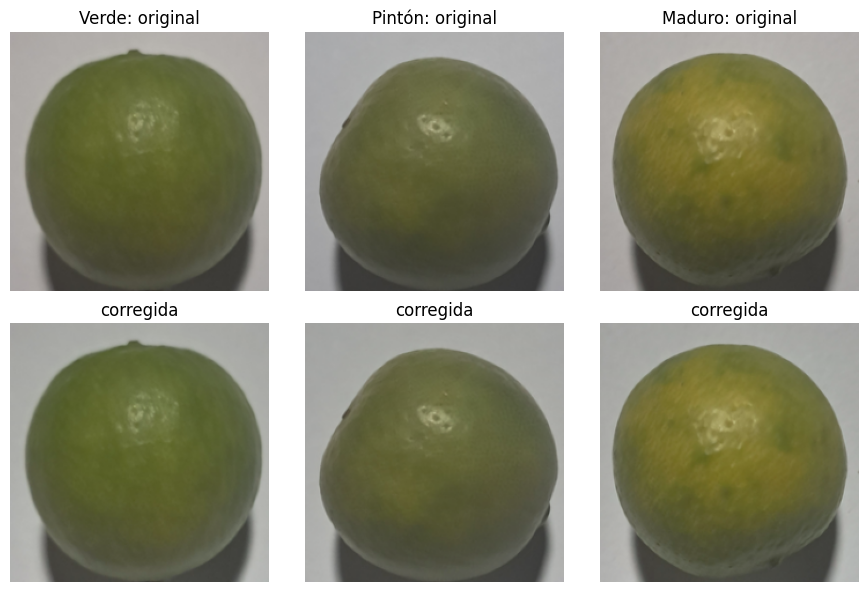

In [13]:
# 4.3 Figura: antes y después de la limpieza  ->  Informe: 4.5 Limpieza y preprocesamiento de señales
fig, ax = plt.subplots(2, 3, figsize=(9, 6))
for k, c in enumerate(CLASES):
    i = df.index[df.clase == c][0]
    ax[0, k].imshow(IMG["cruda"][i][:, :, ::-1]); ax[0, k].set_title(f"{NOMBRE[c]}: original")
    ax[1, k].imshow(IMG["corregida"][i][:, :, ::-1]); ax[1, k].set_title("corregida")
for a in ax.flat: a.axis("off")
guardar_fig("fig_antes_despues.png")

## 5. Color del limón
**Informe:** 4.6 Extracción de características (descriptores de color)

In [14]:
# 5.1 Tono del limón  ->  Informe: 4.6 Extracción de características (descriptores de color)
# OpenCV usa tono de 0 a 179: amarillo ~ 20-30, verde ~ 35-45
def hue_limon(bgr, m):
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)[:, :, 0][m > 0].astype(int)

HUES = [hue_limon(im, mk) for im, mk in zip(IMG["corregida"], MASK)]
df["tono_mediano"] = [np.median(h) if len(h) else np.nan for h in HUES]
print(df.groupby("clase").tono_mediano.describe().reindex(CLASES).round(1))

        count  mean  std   min   25%   50%   75%   max
clase                                                 
verde    96.0  39.4  4.2  33.0  37.0  39.0  41.0  57.0
pinton   43.0  31.6  1.7  28.0  30.5  32.0  32.5  35.0
maduro   88.0  25.2  2.7  19.0  23.8  26.0  27.0  31.0


## 6. Partición y calidad de etiquetas
**Informe:** 4.4 Partición de datos (Tabla 8) · 4.3 Exploración inicial (Tabla 7)

In [15]:
# 6.1 Partición estratificada 70/15/15 por imagen  ->  Informe: 4.4 Partición de datos (Tabla 8) · 4.3 Exploración inicial (Tabla 7)
def particionar(df, seed=SEED):
    """df: una fila por imagen (un limón por foto) con columnas archivo y clase."""
    train, resto = train_test_split(df, test_size=0.30, stratify=df["clase"], random_state=seed)
    val, test = train_test_split(resto, test_size=0.50, stratify=resto["clase"], random_state=seed)
    df = df.copy()
    df.loc[train.index, "particion"] = "train"
    df.loc[val.index, "particion"] = "val"
    df.loc[test.index, "particion"] = "test"
    assert df["ruta"].is_unique                     # cada imagen aparece una sola vez
    return df

df = particionar(df)
TR, VA, TE = (np.where(df.particion == p)[0] for p in ("train", "val", "test"))
y = df.y.values
print(f"train {len(TR)} | val {len(VA)} | test {len(TE)}")

train 158 | val 34 | test 35


In [16]:
# 6.2 Tabla 8: partición por clase  ->  Informe: 4.4 Partición de datos (Tabla 8) · 4.3 Exploración inicial (Tabla 7)
t8 = pd.crosstab(df.particion, df.clase).reindex(index=["train", "val", "test"], columns=CLASES)
t8.columns = [NOMBRE[c] for c in CLASES]
t8.index = ["Entrenamiento", "Validación", "Prueba"]
t8 = t8.reset_index().rename(columns={"index": "Conjunto"})
guardar_tabla(t8, "tabla08_particion", "Tabla 8. Partición por clase")
df.drop(columns=["ruta"]).to_csv(os.path.join(TAB, "particion.csv"), index=False, encoding="utf-8-sig")


=== Tabla 8. Partición por clase ===
     Conjunto  Verde  Pintón  Maduro
Entrenamiento     67      30      61
   Validación     14       7      13
       Prueba     15       6      14


In [17]:
# 6.3 Porcentaje de superficie amarilla  ->  Informe: 4.4 Partición de datos (Tabla 8) · 4.3 Exploración inicial (Tabla 7)
# El umbral de tono es FIJO (UMBRAL_H_FIJO, celda 2.2). Además se calcula, solo con entrenamiento, el umbral que mejor
# reproduciría las etiquetas: NO se usa, sirve como alerta (si se aleja mucho de 27, hay etiquetas que revisar).
def pct_amarillo(h, umbral): return 100 * (h < umbral).mean() if len(h) else np.nan
def clase_por_pct(p): return 0 if p < 10 else (1 if p <= 30 else 2)
UMBRAL_H = UMBRAL_H_FIJO
UMBRAL_CAL = max(range(22, 38), key=lambda u: np.mean([clase_por_pct(pct_amarillo(HUES[i], u)) == y[i] for i in TR]))
df["pct_amarillo"] = [pct_amarillo(h, UMBRAL_H) for h in HUES]
df["clase_por_pct"] = df.pct_amarillo.map(clase_por_pct)
coinc = (df.clase_por_pct == df.y).mean() * 100
anotar(f"\nUmbral de tono FIJO: H < {UMBRAL_H} (escala OpenCV 0-179) se considera amarillo.")
anotar(f"Alerta: con las etiquetas de entrenamiento, el umbral que más coincidiría sería H < {UMBRAL_CAL}"
       + (" (lejos del fijo: revisar etiquetas)." if abs(UMBRAL_CAL - UMBRAL_H) >= 3 else " (cerca del fijo)."))
anotar(f"Coincidencia entre % amarillo medido y etiqueta humana: {coinc:.1f} % ({(df.clase_por_pct == df.y).sum()} de {len(df)}).")
desac = df[df.clase_por_pct != df.y][["clase", "archivo", "pct_amarillo"]].copy()
desac["clase_segun_pct"] = df.clase_por_pct[desac.index].map(dict(enumerate(CLASES)))
desac.to_csv(os.path.join(TAB, "desacuerdos_pct_vs_etiqueta.csv"), index=False, encoding="utf-8-sig")
print(desac.round(1).to_string(index=False))


Umbral de tono FIJO: H < 27 (escala OpenCV 0-179) se considera amarillo.
Alerta: con las etiquetas de entrenamiento, el umbral que más coincidiría sería H < 31 (lejos del fijo: revisar etiquetas).
Coincidencia entre % amarillo medido y etiqueta humana: 79.3 % (180 de 227).
 clase                   archivo  pct_amarillo clase_segun_pct
maduro         Ark/m_A26_653.jpg           3.3           verde
maduro         Ark/m_A26_652.jpg          22.8          pinton
maduro         Ark/m_A26_647.jpg           6.2           verde
maduro         Ark/m_A26_644.jpg          25.7          pinton
maduro         Ark/m_A26_639.jpg          27.8          pinton
maduro         Ark/m_A26_636.jpg          17.2          pinton
maduro         Ark/m_A26_627.jpg           4.1           verde
maduro         Ark/m_A26_626.jpg           0.0           verde
maduro         Ark/m_A26_624.jpg           9.6           verde
pinton         Ark/p_A26_644.jpg           0.2           verde
pinton         Ark/p_A26_640.jpg

In [18]:
# 6.4 Tabla 7: problemas de calidad  ->  Informe: 4.4 Partición de datos (Tabla 8) · 4.3 Exploración inicial (Tabla 7)
t7 = pd.DataFrame([
    dict(Problema="Imágenes borrosas", Cantidad=int(df_todo.borrosa.sum()), Acción="Repetir la captura o retirar."),
    dict(Problema="Duplicados", Cantidad=len(dups), Acción="Conservar una por grupo."),
    dict(Problema="Etiquetas en desacuerdo entre los dos integrantes", Cantidad="(registrar a mano)", Acción="Revisión conjunta con la Tabla 5."),
    dict(Problema="Desacuerdo entre % amarillo medido y etiqueta humana", Cantidad=len(desac),
         Acción=f"Revisión conjunta; coincidencia {coinc:.1f} %."),
])
guardar_tabla(t7, "tabla07_calidad", "Tabla 7. Problemas de calidad")


=== Tabla 7. Problemas de calidad ===
                                            Problema           Cantidad                                  Acción
                                   Imágenes borrosas                  0           Repetir la captura o retirar.
                                          Duplicados                  9                Conservar una por grupo.
   Etiquetas en desacuerdo entre los dos integrantes (registrar a mano)       Revisión conjunta con la Tabla 5.
Desacuerdo entre % amarillo medido y etiqueta humana                 47 Revisión conjunta; coincidencia 79.3 %.


## 7. Exploración visual (EDA)
**Informe:** 4.3 Exploración inicial de los datos

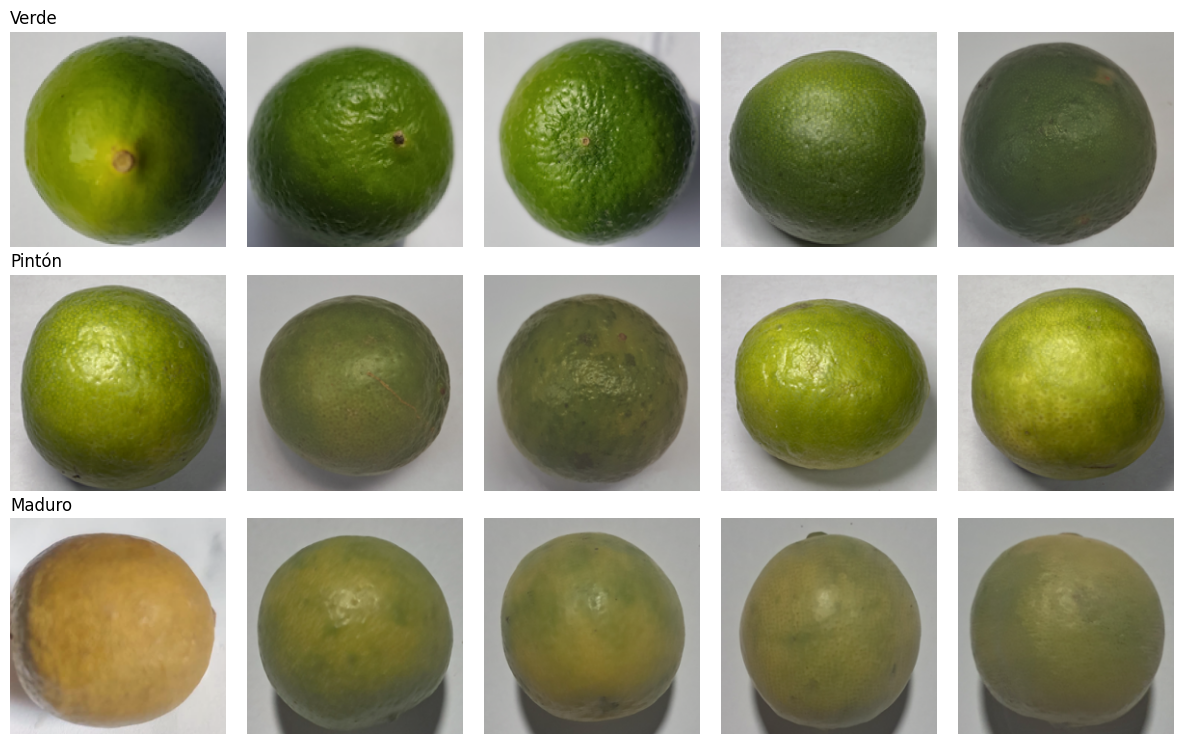

In [19]:
# 7.1 Figura: muestras por clase  ->  Informe: 4.3 Exploración inicial de los datos
fig, ax = plt.subplots(3, 5, figsize=(12, 7.5))
for k, c in enumerate(CLASES):
    idx = df.index[df.clase == c].tolist()
    sel = np.random.RandomState(SEED).choice(idx, min(5, len(idx)), replace=False)
    for j in range(5):
        ax[k, j].axis("off")
        if j < len(sel): ax[k, j].imshow(IMG["corregida"][sel[j]][:, :, ::-1])
    ax[k, 0].set_title(NOMBRE[c], loc="left")
guardar_fig("fig_muestras_por_clase.png")

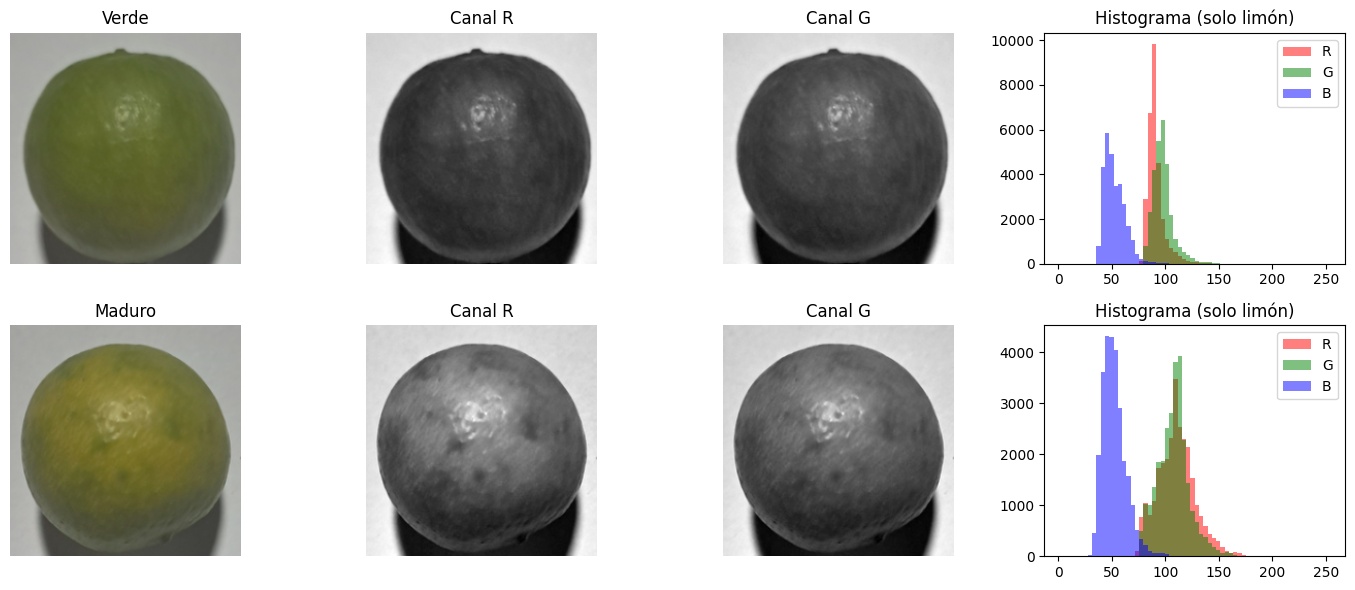

In [20]:
# 7.2 Figura: canales RGB e histogramas (Verde vs. Maduro)  ->  Informe: 4.3 Exploración inicial de los datos
fig, ax = plt.subplots(2, 4, figsize=(14, 6))
for k, c in enumerate(["verde", "maduro"]):
    i = df.index[df.clase == c][0]; im, mk = IMG["corregida"][i], MASK[i]
    ax[k, 0].imshow(im[:, :, ::-1]); ax[k, 0].set_title(NOMBRE[c]); ax[k, 0].axis("off")
    for j, (nom, ch, col) in enumerate([("R", 2, "red"), ("G", 1, "green"), ("B", 0, "blue")]):
        if j < 2:
            ax[k, j + 1].imshow(im[:, :, ch], cmap="gray"); ax[k, j + 1].set_title(f"Canal {nom}"); ax[k, j + 1].axis("off")
        ax[k, 3].hist(im[:, :, ch][mk > 0], bins=64, range=(0, 255), color=col, alpha=0.5, label=nom)
    ax[k, 3].set_title("Histograma (solo limón)"); ax[k, 3].legend()
guardar_fig("fig_canales_rgb.png")

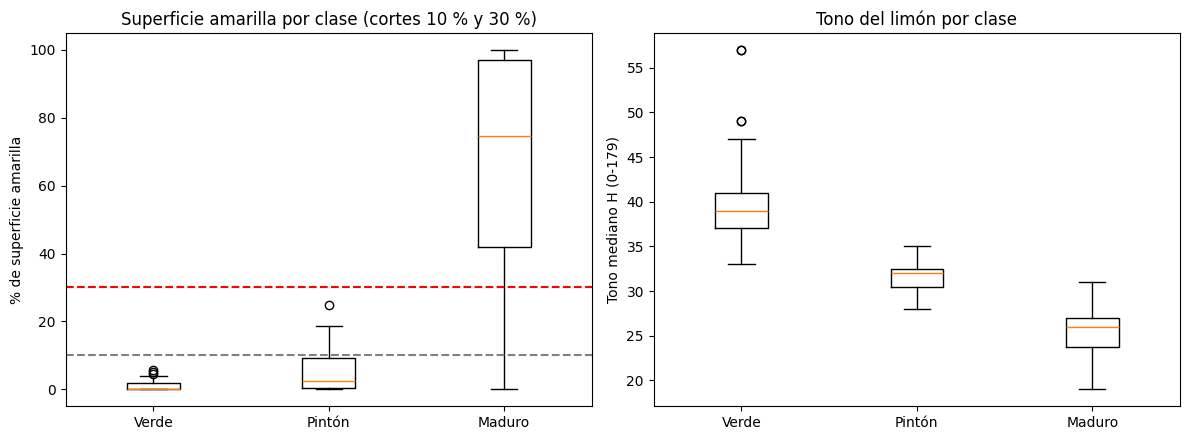

In [21]:
# 7.3 Figura: % de superficie amarilla y tono por clase  ->  Informe: 4.3 Exploración inicial de los datos
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].boxplot([df.pct_amarillo[df.clase == c] for c in CLASES]); ax[0].set_xticks([1, 2, 3], [NOMBRE[c] for c in CLASES])
ax[0].axhline(10, ls="--", c="gray"); ax[0].axhline(30, ls="--", c="red")
ax[0].set_ylabel("% de superficie amarilla"); ax[0].set_title("Superficie amarilla por clase (cortes 10 % y 30 %)")
ax[1].boxplot([df.tono_mediano[df.clase == c] for c in CLASES]); ax[1].set_xticks([1, 2, 3], [NOMBRE[c] for c in CLASES])
ax[1].set_ylabel("Tono mediano H (0-179)"); ax[1].set_title("Tono del limón por clase")
guardar_fig("fig_amarillo_y_tono.png")

## 8. Análisis espectral
**Informe:** 4.6 Análisis espectral (FFT y wavelet)

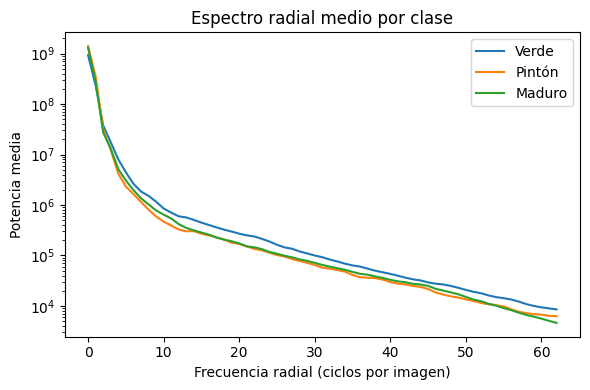

In [22]:
# 8.1 Transformada de Fourier (FFT 2D)  ->  Informe: 4.6 Análisis espectral (FFT y wavelet)
def gris128(im, mk):
    g = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY).astype(np.float32)
    g[mk == 0] = g[mk > 0].mean() if (mk > 0).any() else g.mean()      # fondo neutro: no aporta bordes
    return cv2.resize(g, (128, 128), interpolation=cv2.INTER_AREA)

hann = np.outer(np.hanning(128), np.hanning(128))
yy, xx = np.indices((128, 128)); rad = np.hypot(yy - 64, xx - 64).astype(int)
def espectro_radial(g):
    F = np.abs(np.fft.fftshift(np.fft.fft2((g - g.mean()) * hann))) ** 2
    return np.bincount(rad.ravel(), F.ravel())[:64] / np.bincount(rad.ravel())[:64]
def bandas(p):
    t = p[1:].sum()
    return [p[1:8].sum() / t, p[8:24].sum() / t, p[24:64].sum() / t]

G = [gris128(im, mk) for im, mk in zip(IMG["corregida"], MASK)]
ESP = np.array([espectro_radial(g) for g in G]); BAND = np.array([bandas(p) for p in ESP])
plt.figure(figsize=(6, 4))
for c in CLASES:
    plt.semilogy(ESP[df.clase == c].mean(0)[1:], label=NOMBRE[c])
plt.xlabel("Frecuencia radial (ciclos por imagen)"); plt.ylabel("Potencia media"); plt.legend(); plt.title("Espectro radial medio por clase")
guardar_fig("fig_fft_radial.png")

In [23]:
# 8.2 Transformada wavelet y tabla espectral  ->  Informe: 4.6 Análisis espectral (FFT y wavelet)
def wavelet(g):
    cA, d2, d1 = pywt.wavedec2(g, "db4", level=2)
    e1, e2 = sum(np.sum(np.square(x)) for x in d1), sum(np.sum(np.square(x)) for x in d2)
    tot = np.sum(np.square(cA)) + e1 + e2
    return [e1 / tot, e2 / tot]           # detalle nivel 1 (fino), nivel 2 (medio)

WAV = np.array([wavelet(g) for g in G])
esp_t = pd.DataFrame({"Clase": [NOMBRE[c] for c in CLASES],
    "FFT baja (1-7) %": [100 * BAND[df.clase == c, 0].mean() for c in CLASES],
    "FFT media (8-23) %": [100 * BAND[df.clase == c, 1].mean() for c in CLASES],
    "FFT alta (24-63) %": [100 * BAND[df.clase == c, 2].mean() for c in CLASES],
    "Wavelet detalle nivel 1 %": [100 * WAV[df.clase == c, 0].mean() for c in CLASES],
    "Wavelet detalle nivel 2 %": [100 * WAV[df.clase == c, 1].mean() for c in CLASES]}).round(3)
guardar_tabla(esp_t, "espectral_por_clase", "Energía espectral por clase (porcentaje de la energía total)")


=== Energía espectral por clase (porcentaje de la energía total) ===
 Clase  FFT baja (1-7) %  FFT media (8-23) %  FFT alta (24-63) %  Wavelet detalle nivel 1 %  Wavelet detalle nivel 2 %
 Verde            98.639               1.099               0.261                      0.037                      0.066
Pintón            99.218               0.640               0.142                      0.019                      0.034
Maduro            99.352               0.532               0.116                      0.016                      0.030


## 9. Baseline clásico
**Informe:** 5.1 Modelo base (baseline clásico)

In [24]:
# 9.1 Descriptores HOG, LBP y color  ->  Informe: 5.1 Modelo base (baseline clásico)
def descriptores(im, mk, h):
    g = cv2.cvtColor(cv2.resize(im, (128, 128), interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2GRAY)
    m = cv2.resize(mk, (128, 128), interpolation=cv2.INTER_NEAREST) > 0
    g_m = np.where(m, g, int(g[m].mean()) if m.any() else 0).astype(np.uint8)
    f_hog = hog(g_m, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2))
    lbp = local_binary_pattern(g_m, P=8, R=1, method="uniform")
    f_lbp = np.histogram(lbp[m], bins=10, range=(0, 10), density=True)[0]
    f_hue = np.histogram(h, bins=18, range=(0, 90), density=True)[0] if len(h) else np.zeros(18)
    lab = cv2.cvtColor(im, cv2.COLOR_BGR2LAB)[mk > 0].astype(float)
    f_col = np.r_[pct_amarillo(h, UMBRAL_H) / 100, lab.mean(0) / 255, lab.std(0) / 255] if len(lab) else np.zeros(7)
    return np.r_[f_hog, f_lbp, f_hue, f_col]

X = np.array([descriptores(im, mk, h) for im, mk, h in zip(IMG["corregida"], MASK, HUES)])
print("Matriz de descriptores:", X.shape)

def metricas(yt, yp):
    yt, yp = np.asarray(yt), np.asarray(yp)
    no_mad = yt != 2                                   # limones verdes o pintones
    return dict(exactitud=accuracy_score(yt, yp), f1_macro=f1_score(yt, yp, labels=[0, 1, 2], average="macro", zero_division=0),
                recall_maduro=recall_score(yt, yp, labels=[2], average="macro", zero_division=0),
                precision_maduro=precision_score(yt, yp, labels=[2], average="macro", zero_division=0),
                fp_maduro=float((yp[no_mad] == 2).mean()) if no_mad.any() else 0.0)   # % de no maduros marcados como maduros

Matriz de descriptores: (227, 8135)


In [25]:
# 9.2 Baseline: SVM con búsqueda de hiperparámetros  ->  Informe: 5.1 Modelo base (baseline clásico)
# validación cruzada sobre entrenamiento + validación; el conjunto de prueba no se toca
TRV = np.r_[TR, VA]
n_split = max(2, min(5, np.bincount(y[TRV]).min()))
def svm_grid(gammas):
    return GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel="rbf", class_weight="balanced")),
                        {"svc__C": [0.1, 1, 10, 100], "svc__gamma": gammas},
                        cv=StratifiedKFold(n_split, shuffle=True, random_state=SEED), scoring="f1_macro")
grid = svm_grid(["scale", 1e-3, 1e-4]).fit(X[TRV], y[TRV])
t0 = time.perf_counter(); pred_svm = grid.predict(X[TE]); lat_svm = (time.perf_counter() - t0) / len(TE) * 1000
m_svm = metricas(y[TE], pred_svm)
anotar(f"\nBaseline SVM: mejores hiperparámetros {grid.best_params_}, F1 macro en CV = {grid.best_score_:.3f}")
anotar(f"Baseline SVM en prueba: " + ", ".join(f"{k} {v:.3f}" for k, v in m_svm.items()) + f", latencia {lat_svm:.2f} ms/muestra")


Baseline SVM: mejores hiperparámetros {'svc__C': 1, 'svc__gamma': 0.0001}, F1 macro en CV = 0.549
Baseline SVM en prueba: exactitud 0.771, f1_macro 0.703, recall_maduro 1.000, precision_maduro 0.700, fp_maduro 0.286, latencia 1.41 ms/muestra


In [26]:
# 9.3 SVM solo con descriptores espectrales y de color  ->  Informe: 5.1 Modelo base (baseline clásico)
Xe = np.c_[BAND, WAV, df.pct_amarillo.values / 100, np.array([np.histogram(h, 18, (0, 90), density=True)[0] for h in HUES])]
m_esp = metricas(y[TE], svm_grid(["scale", 1e-2, 1e-3]).fit(Xe[TRV], y[TRV]).predict(Xe[TE]))
print("SVM espectral en prueba:", {k: round(v, 3) for k, v in m_esp.items()})

SVM espectral en prueba: {'exactitud': 0.914, 'f1_macro': 0.897, 'recall_maduro': 0.929, 'precision_maduro': 1.0, 'fp_maduro': 0.0}


## 10. ResNet18
**Informe:** 5.2 Arquitectura · 5.4 Entrenamiento · 6.1 Protocolo · 6.2 Métricas comparativas

In [27]:
# 10.1 Dataset de PyTorch y modelo ResNet18  ->  Informe: 5.2 Arquitectura · 5.4 Entrenamiento · 6.1 Protocolo · 6.2 Métricas comparativas
MEDIA, DESV = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
aug = transforms.Compose([transforms.ToPILImage(), transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
                          transforms.RandomRotation(180), transforms.ColorJitter(brightness=0.15),   # sin cambiar el tono
                          transforms.ToTensor(), transforms.Normalize(MEDIA, DESV)])
sin_aug = transforms.Compose([transforms.ToPILImage(), transforms.ToTensor(), transforms.Normalize(MEDIA, DESV)])

class DS(torch.utils.data.Dataset):
    def __init__(s, imgs, idx, tf): s.imgs, s.idx, s.tf = imgs, idx, tf
    def __len__(s): return len(s.idx)
    def __getitem__(s, k):
        i = s.idx[k]; return s.tf(np.ascontiguousarray(s.imgs[i][:, :, ::-1])), int(y[i])

def crear_resnet():
    try:
        net = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    except Exception as e:
        print("No se pudieron descargar los pesos de ImageNet, se usa inicialización aleatoria:", e)
        net = models.resnet18(weights=None)
    for nombre, p in net.named_parameters():                       # congelar hasta layer3
        p.requires_grad = nombre.startswith("layer4")
    net.fc = nn.Linear(512, len(CLASES))                           # cabeza nueva: FC(512 -> 3)
    return net.to(DEVICE)

def predecir(net, imgs, idx):
    net.eval(); out = []
    with torch.no_grad():
        for xb, _ in torch.utils.data.DataLoader(DS(imgs, idx, sin_aug), batch_size=32):
            out.append(torch.softmax(net(xb.to(DEVICE)), 1).cpu())
    return torch.cat(out).numpy()

MLDB = os.path.join(BASE, "mlflow.db")
mlflow.set_tracking_uri("sqlite:///" + MLDB)
mlflow.set_experiment("limon_madurez")
print("Modelo listo en", DEVICE)

2026/11/16 17:17:22 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/16 17:17:22 INFO mlflow.store.db.utils: Updating database tables
2026/11/16 17:17:24 INFO mlflow.tracking.fluent: Experiment with name 'limon_madurez' does not exist. Creating a new experiment.


Modelo listo en cuda


In [28]:
# 10.2 Función de entrenamiento (registro en MLflow)  ->  Informe: 5.2 Arquitectura · 5.4 Entrenamiento · 6.1 Protocolo · 6.2 Métricas comparativas
def entrenar(variante="corregida", seed=SEED, epocas=EPOCAS):
    fijar_semilla(seed)
    imgs = IMG[variante]; net = crear_resnet()
    peso = torch.tensor(len(TR) / (len(CLASES) * np.bincount(y[TR], minlength=3).clip(1)), dtype=torch.float32)
    crit = nn.CrossEntropyLoss(weight=peso.to(DEVICE))
    opt = torch.optim.AdamW([p for p in net.parameters() if p.requires_grad], lr=LR, weight_decay=1e-4)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epocas)
    dl = torch.utils.data.DataLoader(DS(imgs, TR, aug), batch_size=16, shuffle=True,
                                     generator=torch.Generator().manual_seed(seed))
    hist, mejor_f1, mejor_estado = [], -1, None
    with mlflow.start_run(run_name=f"resnet18_{variante}_s{seed}"):
        mlflow.log_params(dict(variante=variante, seed=seed, epocas=epocas, lr=LR, batch=16, congeladas="conv1-layer3", tam=TAM))
        for ep in range(epocas):
            net.train(); tot = 0
            for xb, yb in dl:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                opt.zero_grad(); loss = crit(net(xb), yb); loss.backward(); opt.step(); tot += loss.item() * len(xb)
            sch.step()
            pv = predecir(net, imgs, VA)
            with torch.no_grad():   # log-probabilidades como logits: softmax(log p) = p
                lv = crit(torch.log(torch.tensor(pv) + 1e-9).to(DEVICE), torch.tensor(y[VA]).to(DEVICE)).item()
            f1v = f1_score(y[VA], pv.argmax(1), average="macro")
            f1t = f1_score(y[TR], predecir(net, imgs, TR).argmax(1), average="macro")
            hist.append(dict(epoca=ep + 1, perdida_train=tot / len(TR), perdida_val=lv, f1_train=f1t, f1_val=f1v))
            mlflow.log_metrics({k: v for k, v in hist[-1].items() if k != "epoca"}, step=ep + 1)
            if f1v > mejor_f1:                                       # se guarda la mejor época según validación
                mejor_f1, mejor_estado = f1v, {k: v.detach().clone() for k, v in net.state_dict().items()}
        net.load_state_dict(mejor_estado)
        t0 = time.perf_counter(); pt = predecir(net, imgs, TE); lat = (time.perf_counter() - t0) / len(TE) * 1000
        m = metricas(y[TE], pt.argmax(1)); m["latencia_ms"] = lat
        mlflow.log_metrics({f"test_{k}": v for k, v in m.items()})
    return net, pt, pd.DataFrame(hist), m

In [29]:
# 10.3 Entrenar ResNet18 con tres semillas  ->  Informe: 5.2 Arquitectura · 5.4 Entrenamiento · 6.1 Protocolo · 6.2 Métricas comparativas
RES, PT = [], []          # métricas y probabilidades en prueba de cada semilla
for s in SEMILLAS:
    net, pt, hist, m = entrenar("corregida", s)
    RES.append(m); PT.append(pt); print(f"semilla {s}: " + ", ".join(f"{k} {v:.3f}" for k, v in m.items()))
    if s == SEMILLAS[0]: net_final, prob_final, hist_final = net, pt, hist
R = pd.DataFrame(RES)
n_param = sum(p.numel() for p in net_final.parameters())

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 171MB/s]


semilla 42: exactitud 0.886, f1_macro 0.857, recall_maduro 0.929, precision_maduro 0.929, fp_maduro 0.048, latencia_ms 2.603
semilla 7: exactitud 0.886, f1_macro 0.857, recall_maduro 1.000, precision_maduro 1.000, fp_maduro 0.000, latencia_ms 3.292
semilla 123: exactitud 0.914, f1_macro 0.896, recall_maduro 1.000, precision_maduro 1.000, fp_maduro 0.000, latencia_ms 2.609


In [30]:
# 10.4 Tabla comparativa y verificación de H1  ->  Informe: 3.4 H1 · 5.1 Baseline · 6.2 Métricas comparativas
ms = lambda s: f"{np.mean(s):.3f} ± {np.std(s, ddof=1):.3f}"   # media ± desv. estándar muestral
fila = lambda nom, m, par, lat: {"Modelo": nom, "Exactitud": f"{m['exactitud']:.3f}", "F1 macro": f"{m['f1_macro']:.3f}",
                                 "Recall Maduro": f"{m['recall_maduro']:.3f}", "Precisión Maduro": f"{m['precision_maduro']:.3f}",
                                 "FP Maduro": f"{m['fp_maduro']:.3f}", "Parámetros": par, "Latencia/muestra": lat}
t_cmp = pd.DataFrame([
    fila("HOG + LBP + color + SVM (baseline)", m_svm, "No aplica", f"{lat_svm:.2f} ms"),
    fila("Descriptores espectrales y de color + SVM (mejor clásico)", m_esp, "No aplica", "—"),
    {"Modelo": "ResNet18", "Exactitud": ms(R.exactitud), "F1 macro": ms(R.f1_macro), "Recall Maduro": ms(R.recall_maduro),
     "Precisión Maduro": ms(R.precision_maduro), "FP Maduro": ms(R.fp_maduro),
     "Parámetros": f"{n_param / 1e6:.1f} M", "Latencia/muestra": f"{R.latencia_ms.mean():.1f} ms ({DEVICE})"}])
guardar_tabla(t_cmp, "tabla_6_2_comparacion", "Sección 6.2. Métricas en prueba (ResNet18: media ± desv. estándar de 3 semillas)")

# H1: ResNet18 debe reducir a la mitad el error (1 - F1) del mejor modelo clásico y tener recall Maduro >= 0.90
F1_CLASICO = m_esp["f1_macro"]
if H1_UMBRAL_FINAL is None:
    H1_UMBRAL = round(1 - (1 - F1_CLASICO) / 2, 3)
    anotar(f"\nH1 — umbral PROVISIONAL (se recalcula en cada avance): F1 macro >= 1 - (1 - {F1_CLASICO:.3f}) / 2 = {H1_UMBRAL:.3f} "
           f"y recall Maduro >= 0.90.")
else:
    H1_UMBRAL = H1_UMBRAL_FINAL
    anotar(f"\nH1 — umbral FIJO de la entrega final: F1 macro >= {H1_UMBRAL:.3f} y recall Maduro >= 0.90 "
           f"(SVM espectral de esta corrida: {F1_CLASICO:.3f}, solo como dato).")
h1 = R.f1_macro.mean() >= H1_UMBRAL and R.recall_maduro.mean() >= 0.90
anotar(f"ResNet18: F1 macro {R.f1_macro.mean():.3f}, recall Maduro {R.recall_maduro.mean():.3f} -> H1 {'SE CUMPLE' if h1 else 'NO se cumple'}.")
anotar(f"Dato: mejora de F1 macro de ResNet18 sobre el baseline HOG: {(R.f1_macro.mean() - m_svm['f1_macro']) * 100:+.1f} puntos.")


=== Sección 6.2. Métricas en prueba (ResNet18: media ± desv. estándar de 3 semillas) ===
                                                   Modelo     Exactitud      F1 macro Recall Maduro Precisión Maduro     FP Maduro Parámetros Latencia/muestra
                       HOG + LBP + color + SVM (baseline)         0.771         0.703         1.000            0.700         0.286  No aplica          1.41 ms
Descriptores espectrales y de color + SVM (mejor clásico)         0.914         0.897         0.929            1.000         0.000  No aplica                —
                                                 ResNet18 0.895 ± 0.016 0.870 ± 0.023 0.976 ± 0.041    0.976 ± 0.041 0.016 ± 0.027     11.2 M    2.8 ms (cuda)

H1 — umbral PROVISIONAL (se recalcula en cada avance): F1 macro >= 1 - (1 - 0.897) / 2 = 0.949 y recall Maduro >= 0.90.
ResNet18: F1 macro 0.870, recall Maduro 0.976 -> H1 NO se cumple.
Dato: mejora de F1 macro de ResNet18 sobre el baseline HOG: +16.7 puntos.


**Métricas por clase y metas del proyecto.** Precisión, recall y F1 de cada clase (media ± desviación de las 3 semillas) y comparación con las metas de la sección 3.3 (definidas en la celda 2.2). Una sola cifra global puede esconder que una clase falla.

In [31]:
# 10.5 Métricas por clase y metas  ->  Informe: 3.3 Objetivos · 6.2 Métricas comparativas · 10.1 Logros
P, Rc, F = (np.array([precision_recall_fscore_support(y[TE], pt.argmax(1), labels=[0, 1, 2], zero_division=0)[k] for pt in PT])
            for k in range(3))                                    # matrices semillas x clases
n_te = np.bincount(y[TE], minlength=3)
t_clase = pd.DataFrame([{"Clase": NOMBRE[c], "N prueba": int(n_te[k]), "Precisión": ms(P[:, k]),
                         "Recall": ms(Rc[:, k]), "F1": ms(F[:, k])} for k, c in enumerate(CLASES)])
guardar_tabla(t_clase, "tabla_metricas_por_clase", "Métricas de ResNet18 por clase en prueba (media ± desv. de 3 semillas)")

VALORES = {k: R[k].values for k in ["exactitud", "f1_macro", "recall_maduro", "precision_maduro", "fp_maduro"]}
VALORES.update(f1_verde=F[:, 0], f1_pinton=F[:, 1], f1_maduro=F[:, 2])
filas = []
for clave, nom, op, meta, porque in METAS:
    v = VALORES[clave].mean()
    ok = v >= meta if op == ">=" else v <= meta
    filas.append({"Métrica": nom, "Meta": f"{op} {meta:.2f}", "Valor (media ± desv.)": ms(VALORES[clave]),
                  "¿Cumple?": "Sí" if ok else "No", "Justificación": porque})
t_metas = pd.DataFrame(filas)
guardar_tabla(t_metas, "tabla_metas", "Metas del proyecto (sección 3.3) frente a ResNet18 en prueba")
anotar(f"Metas cumplidas: {(t_metas['¿Cumple?'] == 'Sí').sum()} de {len(t_metas)}. "
       f"Ojo: con {len(TE)} fotos de prueba, una foto equivale a {100 / len(TE):.1f} puntos de exactitud.")


=== Métricas de ResNet18 por clase en prueba (media ± desv. de 3 semillas) ===
 Clase  N prueba     Precisión        Recall            F1
 Verde        15 0.974 ± 0.044 0.822 ± 0.038 0.892 ± 0.036
Pintón         6 0.639 ± 0.024 0.889 ± 0.096 0.743 ± 0.049
Maduro        14 0.976 ± 0.041 0.976 ± 0.041 0.976 ± 0.041

=== Metas del proyecto (sección 3.3) frente a ResNet18 en prueba ===
                   Métrica    Meta Valor (media ± desv.) ¿Cumple?                                                               Justificación
                 Exactitud >= 0.85         0.895 ± 0.016       Sí                 Igual o mejor que un inspector humano (~80-85 %, See, 2015)
                  F1 macro >= 0.85         0.870 ± 0.023       Sí           Similar a lo publicado con ~200 fotos (melón, 230 fotos: F1 0.87)
             Recall Maduro >= 0.90         0.976 ± 0.041       Sí Clase crítica: un maduro que pasa como fresco (NTP 011.006, >30 % amarillo)
          Precisión Maduro >= 0.90         0.9

**Intervalo de confianza de Wilson (95 %).** Con pocas fotos de prueba, un recall de 1.000 puede venir de muy pocos maduros. El intervalo indica entre qué valores podría estar el recall real; responde a la observación del profesor sobre el recall de Maduro.

In [32]:
# 10.6 Intervalo de Wilson para recall de Maduro y exactitud  ->  Informe: 6.2 Métricas comparativas · 9.1 Desafíos
def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; c = (p + z * z / (2 * n)) / (1 + z * z / n); m = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return (max(0.0, c - m), min(1.0, c + m))
mad = y[TE] == 2
filas = []
for s, pt in zip(SEMILLAS, PT):
    pr = pt.argmax(1)
    k_r, n_r = int((pr[mad] == 2).sum()), int(mad.sum())
    k_e, n_e = int((pr == y[TE]).sum()), len(TE)
    (a, b), (c, d) = wilson(k_r, n_r), wilson(k_e, n_e)
    filas.append({"Semilla": s, "Recall Maduro": f"{k_r}/{n_r} = {k_r / max(n_r, 1):.3f}", "IC 95 % recall": f"[{a:.2f}, {b:.2f}]",
                  "Exactitud": f"{k_e}/{n_e} = {k_e / n_e:.3f}", "IC 95 % exactitud": f"[{c:.2f}, {d:.2f}]"})
guardar_tabla(pd.DataFrame(filas), "tabla_wilson", "Intervalos de confianza de Wilson al 95 % (ResNet18, prueba)")


=== Intervalos de confianza de Wilson al 95 % (ResNet18, prueba) ===
 Semilla Recall Maduro IC 95 % recall     Exactitud IC 95 % exactitud
      42 13/14 = 0.929   [0.69, 0.99] 31/35 = 0.886      [0.74, 0.95]
       7 14/14 = 1.000   [0.78, 1.00] 31/35 = 0.886      [0.74, 0.95]
     123 14/14 = 1.000   [0.78, 1.00] 32/35 = 0.914      [0.78, 0.97]


**Desempeño por celular (sección 6.4, obligatoria).** Resultados de ResNet18 en prueba separados por el celular que tomó la foto. Si un celular tiene pocas fotos de prueba, su resultado es poco confiable y eso también se reporta.

In [33]:
# 10.7 Desempeño desagregado por celular  ->  Informe: 6.4 Desempeño desagregado · 9.2 Ética y sesgos
cel_te = df.celular.values[TE]
filas = []
for c in sorted(set(cel_te)):
    sel = cel_te == c; yt = y[TE][sel]; n = np.bincount(yt, minlength=3)
    ex = np.array([accuracy_score(yt, pt.argmax(1)[sel]) for pt in PT])
    f1 = np.array([f1_score(yt, pt.argmax(1)[sel], labels=sorted(set(yt)), average="macro", zero_division=0) for pt in PT])
    rm = np.array([recall_score(yt, pt.argmax(1)[sel], labels=[2], average="macro", zero_division=0) for pt in PT])
    filas.append({"Celular": c, "N": int(sel.sum()), "Verde": int(n[0]), "Pintón": int(n[1]), "Maduro": int(n[2]),
                  "Exactitud": ms(ex), "F1 macro": ms(f1), "Recall Maduro": ms(rm) if n[2] else "sin maduros",
                  "Nota": "pocas fotos" if sel.sum() < 10 else ""})
t_cel = pd.DataFrame(filas)
guardar_tabla(t_cel, "tabla_6_4_por_celular", "Sección 6.4. Desempeño de ResNet18 por celular (prueba, media ± desv. de 3 semillas)")
if (t_cel.N < 10).any():
    anotar("Celulares con menos de 10 fotos de prueba: su resultado no es confiable; se reporta como limitación (sección 9.2).")


=== Sección 6.4. Desempeño de ResNet18 por celular (prueba, media ± desv. de 3 semillas) ===
Celular  N  Verde  Pintón  Maduro     Exactitud      F1 macro Recall Maduro        Nota
    A26 21     12       4       5 0.841 ± 0.027 0.832 ± 0.028 1.000 ± 0.000            
 FRANCO  8      1       0       7 0.958 ± 0.072 0.987 ± 0.022 0.952 ± 0.082 pocas fotos
LEONCIO  2      0       2       0 1.000 ± 0.000 1.000 ± 0.000   sin maduros pocas fotos
   RN10  4      2       0       2 1.000 ± 0.000 1.000 ± 0.000 1.000 ± 0.000 pocas fotos
Celulares con menos de 10 fotos de prueba: su resultado no es confiable; se reporta como limitación (sección 9.2).


## 11. Comparación de entradas
**Informe:** 5.3 Percepción multimodal y fusión de datos

In [34]:
# 11.1 Comparación de entradas (una semilla)  ->  Informe: 5.3 Percepción multimodal y fusión de datos
abl = []
for var, nom in [("cruda", "RGB sin corrección"), ("corregida", "RGB con corrección de iluminación y balance de blancos"),
                 ("clahe", "RGB corregido + CLAHE en el canal L")]:
    m = RES[0] if var == "corregida" else entrenar(var, SEED)[3]
    abl.append({"Entrada": nom, "Exactitud": round(m["exactitud"], 3), "F1 macro": round(m["f1_macro"], 3), "Recall Maduro": round(m["recall_maduro"], 3)})
abl.append({"Entrada": "Descriptores espectrales y de color (FFT, wavelet, % amarillo) + SVM",
            "Exactitud": round(m_esp["exactitud"], 3), "F1 macro": round(m_esp["f1_macro"], 3), "Recall Maduro": round(m_esp["recall_maduro"], 3)})
guardar_tabla(pd.DataFrame(abl), "tabla_5_3_entradas", "Sección 5.3. Comparación de entradas (prueba, semilla 42)")


=== Sección 5.3. Comparación de entradas (prueba, semilla 42) ===
                                                             Entrada  Exactitud  F1 macro  Recall Maduro
                                                  RGB sin corrección      0.857     0.828          0.929
              RGB con corrección de iluminación y balance de blancos      0.886     0.857          0.929
                                 RGB corregido + CLAHE en el canal L      0.886     0.857          1.000
Descriptores espectrales y de color (FFT, wavelet, % amarillo) + SVM      0.914     0.897          0.929


## 12. Evaluación del modelo
**Informe:** 6.3 Matriz de confusión y análisis de errores · 6.5 Visualizaciones

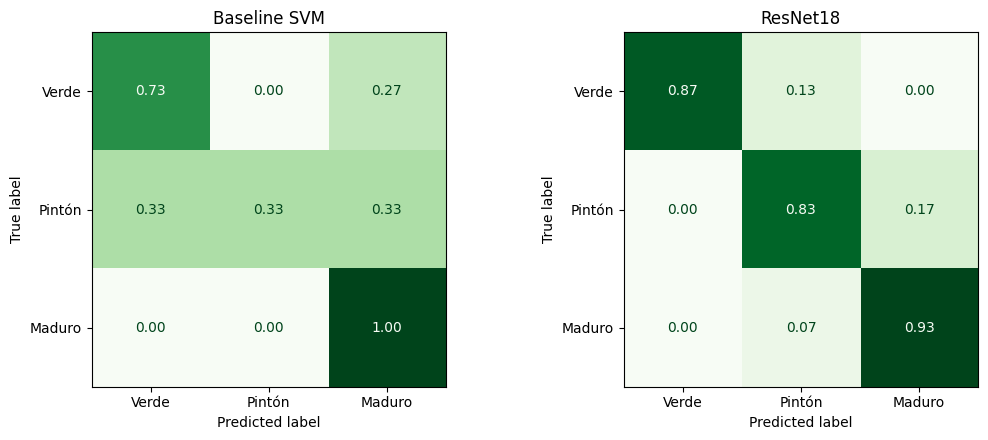

In [35]:
# 12.1 Matriz de confusión normalizada  ->  Informe: 6.3 Matriz de confusión y análisis de errores · 6.5 Visualizaciones
pred_final = prob_final.argmax(1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for a, (p, t) in zip(ax, [(pred_svm, "Baseline SVM"), (pred_final, "ResNet18")]):
    ConfusionMatrixDisplay(confusion_matrix(y[TE], p, labels=[0, 1, 2], normalize="true"),
                           display_labels=[NOMBRE[c] for c in CLASES]).plot(ax=a, cmap="Greens", values_format=".2f", colorbar=False)
    a.set_title(t)
guardar_fig("fig_matriz_confusion.png")

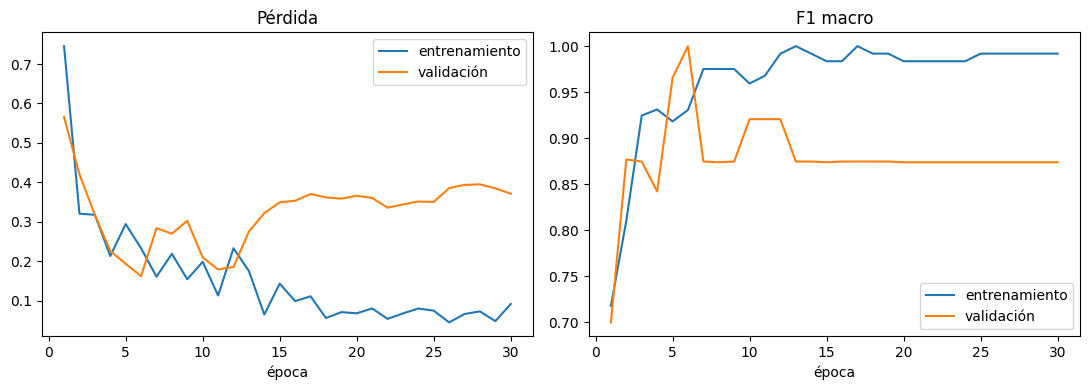

In [36]:
# 12.2 Curvas de pérdida y F1 por época  ->  Informe: 6.3 Matriz de confusión y análisis de errores · 6.5 Visualizaciones
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist_final.epoca, hist_final.perdida_train, label="entrenamiento"); ax[0].plot(hist_final.epoca, hist_final.perdida_val, label="validación")
ax[0].set_title("Pérdida"); ax[0].set_xlabel("época"); ax[0].legend()
ax[1].plot(hist_final.epoca, hist_final.f1_train, label="entrenamiento"); ax[1].plot(hist_final.epoca, hist_final.f1_val, label="validación")
ax[1].set_title("F1 macro"); ax[1].set_xlabel("época"); ax[1].legend()
guardar_fig("fig_curvas.png")

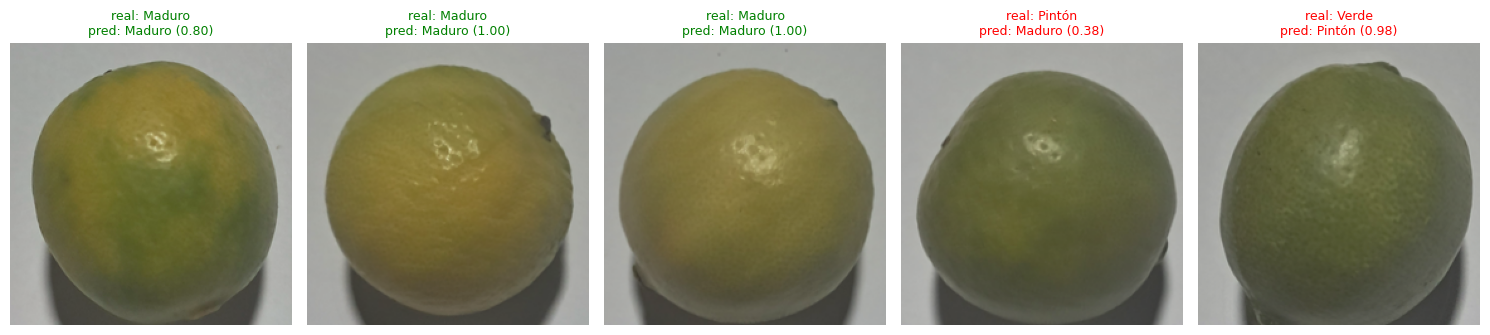


Errores de ResNet18 en prueba:
 clase                 archivo  pct_amarillo prediccion
pinton       Ark/p_A26_644.jpg           0.2     maduro
 verde       Ark/v_A26_661.jpg           0.0     pinton
 verde       Ark/v_A26_659.jpg           0.0     pinton
maduro Franco/m_FRANCO_222.jpg          25.9     pinton


In [37]:
# 12.3 Ejemplos de aciertos y errores  ->  Informe: 6.3 Matriz de confusión y análisis de errores · 6.5 Visualizaciones
ok = [i for i in range(len(TE)) if pred_final[i] == y[TE][i]]
err = [i for i in range(len(TE)) if pred_final[i] != y[TE][i]]
sel = ok[:3] + err[:2]
if sel:
    fig, ax = plt.subplots(1, len(sel), figsize=(3 * len(sel), 3.4), squeeze=False)
    for a, i in zip(ax[0], sel):
        a.imshow(IMG["corregida"][TE[i]][:, :, ::-1]); a.axis("off")
        a.set_title(f"real: {NOMBRE[CLASES[y[TE][i]]]}\npred: {NOMBRE[CLASES[pred_final[i]]]} ({prob_final[i].max():.2f})",
                    color="green" if i in ok else "red", fontsize=9)
    guardar_fig("fig_ejemplos_prediccion.png")
errores = df.iloc[TE[err]][["clase", "archivo", "pct_amarillo"]].assign(prediccion=[CLASES[pred_final[i]] for i in err])
errores.to_csv(os.path.join(TAB, "errores_resnet.csv"), index=False, encoding="utf-8-sig")
anotar("\nErrores de ResNet18 en prueba:\n" + (errores.round(1).to_string(index=False) if len(errores) else "ninguno"))

<sys>:0: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.


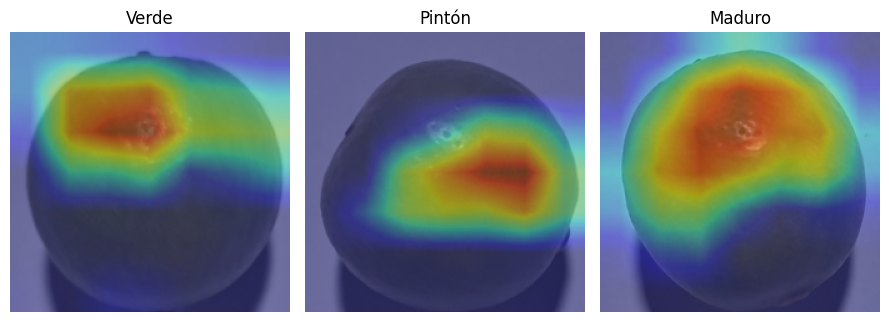

In [38]:
# 12.4 Grad-CAM: ¿el modelo mira la cáscara o el fondo?  ->  Informe: 6.3 Matriz de confusión y análisis de errores · 6.5 Visualizaciones
def gradcam(net, img):
    act, grad = {}, {}
    h1 = net.layer4.register_forward_hook(lambda m, i, o: act.update(v=o))
    h2 = net.layer4.register_full_backward_hook(lambda m, gi, go: grad.update(v=go[0]))
    net.eval(); x = sin_aug(np.ascontiguousarray(img[:, :, ::-1]))[None].to(DEVICE)
    out = net(x); net.zero_grad(); out[0, out.argmax()].backward()
    h1.remove(); h2.remove()
    cam = torch.relu((grad["v"].mean((2, 3), keepdim=True) * act["v"]).sum(1))[0].detach().cpu().numpy()
    return cv2.resize(cam / (cam.max() + 1e-9), (TAM, TAM))

fig, ax = plt.subplots(1, 3, figsize=(9, 3.2))
for a, c in zip(ax, CLASES):
    cand = [i for i in TE if df.clase[i] == c]
    a.axis("off")
    if not cand: continue
    i = cand[0]; a.imshow(IMG["corregida"][i][:, :, ::-1]); a.imshow(gradcam(net_final, IMG["corregida"][i]), cmap="jet", alpha=0.4)
    a.set_title(NOMBRE[c])
guardar_fig("fig_gradcam.png")

## 13. Datos técnicos
**Informe:** 4.8 Herramientas utilizadas · 5.4 Proceso de entrenamiento

In [39]:
# 13.1 Datos técnicos: versiones, hardware y parámetros  ->  Informe: 4.8 Herramientas utilizadas · 5.4 Proceso de entrenamiento
try:
    from torchinfo import summary
    open(os.path.join(TAB, "resnet18_torchinfo.txt"), "w").write(str(summary(net_final, input_size=(1, 3, TAM, TAM), verbose=0)))
except Exception as e:
    print("torchinfo no disponible:", e)
n_entrenables = sum(p.numel() for n_, p in net_final.named_parameters() if n_.startswith(("layer4", "fc")))
anotar(f"\nParámetros ResNet18: {n_param:,} totales, {n_entrenables:,} entrenables (layer4 + fc).")
anotar(f"Versiones: Python {platform.python_version()}, PyTorch {torch.__version__}, torchvision {torchvision.__version__}, "
       f"MLflow {mlflow.__version__}, OpenCV {cv2.__version__}")
anotar(f"Hardware: {'GPU ' + torch.cuda.get_device_name(0) if DEVICE == 'cuda' else 'CPU ' + platform.processor()}")
anotar(f"Entrenamiento: {EPOCAS} épocas, lote 16, AdamW lr {LR} con decaimiento coseno, "
       f"pesos por clase {np.round(len(TR) / (3 * np.bincount(y[TR])), 2).tolist()}, imágenes de {TAM}x{TAM}, prueba con {len(TE)} imágenes.")


Parámetros ResNet18: 11,178,051 totales, 8,395,267 entrenables (layer4 + fc).
Versiones: Python 3.13.16, PyTorch 2.14.1+cu130, torchvision 0.29.1+cu130, MLflow 3.18.0, OpenCV 4.14.0
Hardware: GPU Tesla T4
Entrenamiento: 30 épocas, lote 16, AdamW lr 0.0001 con decaimiento coseno, pesos por clase [0.79, 1.76, 0.86], imágenes de 224x224, prueba con 35 imágenes.


**Exportar el modelo final.** Se guarda la ResNet18 de la semilla 42 (mejor época según validación) en formato TorchScript, que se puede cargar sin el código de entrenamiento. Este archivo es el que usarán el pipeline de Spark (sección 7) y la API en Docker (sección 8). Junto a él se guarda `modelo_info.json` (clases, preprocesamiento, métricas, huella SHA-256) y `preprocesamiento.py` (las funciones de limpieza).

In [40]:
# 13.2 Exportar el modelo final (TorchScript)  ->  Informe: 5.4 Modelo final · 8.1 Servicio de inferencia · 8.3 Registro
#@markdown (Opcional) Enlace de una carpeta de Drive donde guardar el modelo. Si queda vacío, el modelo solo va dentro de resultados.zip.
CARPETA_MODELO = ""  #@param {type:"string"}
MOD = os.path.join(SALIDA, "modelo"); os.makedirs(MOD, exist_ok=True)
net_cpu = copy.deepcopy(net_final).cpu().eval()
ts = torch.jit.trace(net_cpu, torch.zeros(1, 3, TAM, TAM))
ruta_pt = os.path.join(MOD, "resnet18_limon.pt"); ts.save(ruta_pt)

# verificación: el modelo exportado da las mismas probabilidades que el original
lote = torch.stack([sin_aug(np.ascontiguousarray(IMG["corregida"][i][:, :, ::-1])) for i in TE[:8]])
with torch.no_grad():
    dif = (torch.softmax(torch.jit.load(ruta_pt)(lote), 1) - torch.softmax(net_cpu(lote), 1)).abs().max().item()

try:                                                    # funciones de limpieza para reutilizar en Spark y en la API
    open(os.path.join(MOD, "preprocesamiento.py"), "w").write(
        "import numpy as np, cv2\nfrom PIL import Image, ImageOps\nTAM = %d\n\n" % TAM
        + "\n\n".join(inspect.getsource(f) for f in (cargar, segmentar, corregir, recortar)))
except (OSError, TypeError) as e:
    print("No se pudo guardar preprocesamiento.py:", e)
info = dict(modelo="ResNet18 (torchvision), layer4 + fc entrenadas", formato="TorchScript", archivo="resnet18_limon.pt",
            clases=CLASES, nombres=[NOMBRE[c] for c in CLASES], entrada=f"tensor 1x3x{TAM}x{TAM}, RGB normalizado",
            media=MEDIA, desv=DESV, salida="logits (aplicar softmax)",
            preprocesamiento="cargar (EXIF, lado 600) -> segmentar (Otsu en S) -> corregir (iluminación y balance de blancos) "
                             f"-> recortar {TAM}x{TAM} -> BGR a RGB -> normalizar con media/desv de ImageNet",
            umbral_h=int(UMBRAL_H), semilla=SEMILLAS[0], seleccion="mejor F1 macro de validación", epocas=EPOCAS,
            n_train=int(len(TR)), n_val=int(len(VA)), n_test=int(len(TE)),
            metricas_prueba={k: round(float(v), 4) for k, v in RES[0].items()},
            fecha=time.strftime("%Y-%m-%d %H:%M"), sha256=hashlib.sha256(open(ruta_pt, "rb").read()).hexdigest())
json.dump(info, open(os.path.join(MOD, "modelo_info.json"), "w", encoding="utf-8"), ensure_ascii=False, indent=2)
anotar(f"\nModelo exportado: modelo/resnet18_limon.pt ({os.path.getsize(ruta_pt) / 1e6:.1f} MB). "
       f"Diferencia máxima de probabilidad frente al original: {dif:.1e}. SHA-256: {info['sha256'][:16]}…")

if EN_COLAB and CARPETA_MODELO.strip():
    from googleapiclient.http import MediaFileUpload
    for f in sorted(glob.glob(os.path.join(MOD, "*"))):
        servicio().files().create(body={"name": os.path.basename(f), "parents": [id_de(CARPETA_MODELO)]},
                                  media_body=MediaFileUpload(f, resumable=True), supportsAllDrives=True, fields="id").execute()
    print("Modelo copiado a la carpeta de Drive.")

/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1006: FutureWarning: `torch.jit.trace` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1145: FutureWarning: `torch.jit.trace_method` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(



Modelo exportado: modelo/resnet18_limon.pt (44.9 MB). Diferencia máxima de probabilidad frente al original: 0.0e+00. SHA-256: 8eec3d12ef05ec32…


## 14. Pipeline por lotes en Spark
**Informe:** 3.3 Objetivo de sistema · 3.4 H2 · 7.4 Evaluación de escalabilidad (adelanto)

In [41]:
# 14.1 Iniciar Spark  ->  Informe: 3.3 Objetivo de sistema · 3.4 H2 · 7.4 Evaluación de escalabilidad (adelanto)
# Spark reparte el procesamiento de las fotos entre los núcleos del procesador (particiones).
# Los datos y el modelo no cambian: es otra forma de ejecutar la misma limpieza y extracción de descriptores.
from pyspark.sql import SparkSession
NUCLEOS = os.cpu_count()
spark = (SparkSession.builder.master(f"local[{NUCLEOS}]").appName("limon_madurez")
         .config("spark.driver.memory", "4g").config("spark.ui.showConsoleProgress", "false").getOrCreate())
sc = spark.sparkContext
sc.setLogLevel("ERROR")
print("Spark", spark.version, "| núcleos disponibles:", NUCLEOS)

Spark 4.0.5 | núcleos disponibles: 2


In [42]:
# 14.2 Tarea que Spark ejecuta sobre cada foto  ->  Informe: 3.3 Objetivo de sistema · 3.4 H2 · 7.4 Evaluación de escalabilidad (adelanto)
# Repite lo mismo que las celdas 3 a 9: leer, segmentar, corregir, recortar y extraer descriptores.
U_H = UMBRAL_H                                  # se copia para enviarlo a los procesos de Spark
def procesar_foto(ruta):
    import hashlib
    md5 = hashlib.md5(open(ruta, "rb").read()).hexdigest()              # integridad del archivo
    bgr, _ = cargar(ruta)
    m = segmentar(bgr)
    im, mk = recortar(corregir(bgr, m), m)
    h = hue_limon(im, mk)
    desc = descriptores(im, mk, h)
    return dict(ruta=ruta, md5=md5, pct_amarillo=float(pct_amarillo(h, U_H)), n_desc=len(desc))

prueba = procesar_foto(df.ruta[0])
print({k: v for k, v in prueba.items() if k != "ruta"})

{'md5': '20aa29da02428894467fd83f802899c2', 'pct_amarillo': 3.26588440440295, 'n_desc': 8135}


In [43]:
# 14.3 Verificación: Spark da los mismos resultados que el proceso normal  ->  Informe: 3.3 Objetivo de sistema · 3.4 H2 · 7.4 Evaluación de escalabilidad (adelanto)
res = sc.parallelize(df.ruta.tolist(), NUCLEOS).map(procesar_foto).collect()
res = pd.DataFrame(res).set_index("ruta").loc[df.ruta]
dif = np.abs(res.pct_amarillo.values - df.pct_amarillo.values).max()
md5_ok = (res.md5.values == df.md5.values).all()
anotar(f"\nSpark procesó {len(res)} fotos. Diferencia máxima de % amarillo frente al proceso secuencial: {dif:.6f}. "
       f"Huellas MD5 iguales al inventario: {'sí' if md5_ok else 'NO'}.")


Spark procesó 227 fotos. Diferencia máxima de % amarillo frente al proceso secuencial: 0.000000. Huellas MD5 iguales al inventario: sí.


1 particiones: 136.92 s
2 particiones: 112.46 s
4 particiones: 109.17 s
8 particiones: 109.73 s

=== Spark: speedup con 500 fotos (2 núcleos disponibles) ===
 Particiones  Tiempo (s)  Speedup  Eficiencia
           1      136.92     1.00        1.00
           2      112.46     1.22        0.61
           4      109.17     1.25        0.62
           8      109.73     1.25        0.62


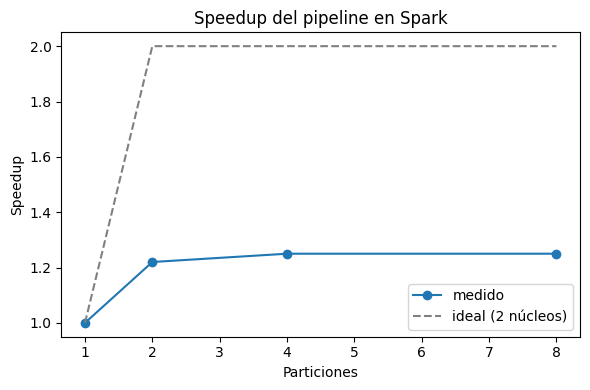

In [44]:
# 14.4 Speedup: tiempo según el número de particiones  ->  Informe: 3.3 Objetivo de sistema · 3.4 H2 · 7.4 Evaluación de escalabilidad (adelanto)
def medir(rutas, particiones, repeticiones=1):
    tiempos = []
    for _ in range(repeticiones):
        t0 = time.perf_counter()
        sc.parallelize(rutas, particiones).map(procesar_foto).count()
        tiempos.append(time.perf_counter() - t0)
    return min(tiempos)

VOLUMEN_SPEEDUP = 500                                                    # fotos procesadas en cada medición
rutas_500 = (df.ruta.tolist() * (VOLUMEN_SPEEDUP // len(df) + 1))[:VOLUMEN_SPEEDUP]
PARTS = sorted({1, 2, 4, 8, NUCLEOS})
filas = []
for p in PARTS:
    t = medir(rutas_500, p)
    filas.append({"Particiones": p, "Tiempo (s)": round(t, 2)})
    print(p, "particiones:", round(t, 2), "s")
t_sp = pd.DataFrame(filas)
t_sp["Speedup"] = (t_sp["Tiempo (s)"].iloc[0] / t_sp["Tiempo (s)"]).round(2)
t_sp["Eficiencia"] = (t_sp["Speedup"] / t_sp["Particiones"].clip(upper=NUCLEOS)).round(2)
guardar_tabla(t_sp, "spark_speedup", f"Spark: speedup con {VOLUMEN_SPEEDUP} fotos ({NUCLEOS} núcleos disponibles)")

plt.figure(figsize=(6, 4))
plt.plot(t_sp.Particiones, t_sp.Speedup, "o-", label="medido")
plt.plot(t_sp.Particiones, np.minimum(t_sp.Particiones, NUCLEOS), "--", c="gray", label=f"ideal ({NUCLEOS} núcleos)")
plt.xlabel("Particiones"); plt.ylabel("Speedup"); plt.title("Speedup del pipeline en Spark"); plt.legend()
guardar_fig("fig_spark_speedup.png")

In [45]:
# 14.5 Escalamiento de volumen: tiempo por foto al crecer el lote  ->  Informe: 3.3 Objetivo de sistema · 3.4 H2 · 7.4 Evaluación de escalabilidad (adelanto)
# Se reutilizan las mismas fotos para simular lotes más grandes (cada foto se vuelve a leer y procesar).
filas = []
for n in [100, 500, 1000]:
    rutas_n = (df.ruta.tolist() * (n // len(df) + 1))[:n]
    t = medir(rutas_n, NUCLEOS, repeticiones=1)
    filas.append({"Fotos": n, "Tiempo (s)": round(t, 2), "ms por foto": round(1000 * t / n, 1)})
    print(n, "fotos:", round(t, 2), "s")
t_vol = pd.DataFrame(filas)
var = 100 * (t_vol["ms por foto"].iloc[-1] - t_vol["ms por foto"].iloc[0]) / t_vol["ms por foto"].iloc[0]
guardar_tabla(t_vol, "spark_volumen", f"Spark: escalamiento de volumen con {NUCLEOS} particiones")
anotar(f"Variación del tiempo por foto entre 100 y 1000 fotos: {var:+.1f} %.")

100 fotos: 23.57 s
500 fotos: 107.57 s
1000 fotos: 214.03 s

=== Spark: escalamiento de volumen con 2 particiones ===
 Fotos  Tiempo (s)  ms por foto
   100       23.57        235.7
   500      107.57        215.1
  1000      214.03        214.0
Variación del tiempo por foto entre 100 y 1000 fotos: -9.2 %.


In [46]:
# 14.6 Registrar la corrida de Spark en MLflow (trazabilidad)  ->  Informe: 3.3 Objetivo de sistema · 3.4 H2 · 7.4 Evaluación de escalabilidad (adelanto)
with mlflow.start_run(run_name="spark_pipeline"):
    mlflow.log_params({"nucleos": NUCLEOS, "volumen_speedup": VOLUMEN_SPEEDUP, "spark": spark.version})
    for r in t_sp.itertuples():
        mlflow.log_metric("tiempo_s", r[2], step=int(r.Particiones)); mlflow.log_metric("speedup", r.Speedup, step=int(r.Particiones))
    mlflow.log_metric("variacion_ms_por_foto_pct", var)
spark.stop()

## 15. Exportación
**Informe:** Todas las secciones

In [47]:
# 15.1 Exportar y descargar resultados.zip  ->  Informe: Todas las secciones
open(os.path.join(SALIDA, "resumen_informe.txt"), "w", encoding="utf-8").write("\n".join(RESUMEN))
df.drop(columns=["ruta"]).to_csv(os.path.join(TAB, "dataset_completo.csv"), index=False, encoding="utf-8-sig")
if os.path.exists(MLDB): shutil.copy(MLDB, os.path.join(SALIDA, "mlflow.db"))   # abrir con: mlflow ui --backend-store-uri sqlite:///mlflow.db
zip_ruta = os.path.join(BASE, "resultados.zip")
with zipfile.ZipFile(zip_ruta, "w", zipfile.ZIP_DEFLATED) as z:
    for f in glob.glob(os.path.join(SALIDA, "**", "*"), recursive=True):
        if os.path.isfile(f): z.write(f, os.path.relpath(f, SALIDA))
print("Listo:", zip_ruta)
if EN_COLAB:
    files.download(zip_ruta)

Listo: /content/resultados.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [48]:
import importlib
for lib in ["numpy", "pandas", "cv2", "skimage", "pywt", "PIL", "matplotlib", "sklearn", "torch", "torchvision", "mlflow", "pyspark", "torchinfo"]:
    try:
        m = importlib.import_module(lib); print(lib, m.__version__)
    except Exception as e:
        print(lib, "no instalado")

numpy 2.4.6
pandas 2.2.3
cv2 4.14.0
skimage 0.25.2
pywt 1.8.0
PIL 11.3.0
matplotlib 3.10.0
sklearn 1.6.1
torch 2.14.1+cu130
torchvision 0.29.1+cu130
mlflow 3.18.0
pyspark 4.0.5
torchinfo 1.8.0
